DESCARGAR BIBLIOTECAS

In [77]:
#%pip install pandas matplotlib

IMPORTAR BIBLIOTECAS

In [78]:
import pandas as pd
import matplotlib.pyplot as plt

GENERAR DATAFRAMES

In [79]:
salario_min = pd.read_csv('DATA/ECONOMIA/indice-salario-minimo-vital-movil-valores-mensuales-pesos-corrientes-desde-1988.csv')

salario_min['indice_tiempo'] = pd.to_datetime(salario_min['indice_tiempo'])
salario_min = salario_min.sort_values(by='indice_tiempo')

salario_min.info()

salario_min.head()

<class 'pandas.DataFrame'>
RangeIndex: 748 entries, 0 to 747
Data columns (total 4 columns):
 #   Column                              Non-Null Count  Dtype         
---  ------                              --------------  -----         
 0   indice_tiempo                       748 non-null    datetime64[us]
 1   salario_minimo_vital_movil_mensual  748 non-null    float64       
 2   salario_minimo_vital_movil_diario   748 non-null    float64       
 3   salario_minimo_vital_movil_hora     748 non-null    float64       
dtypes: datetime64[us](1), float64(3)
memory usage: 23.5 KB


,indice_tiempo,salario_minimo_vital_movil_mensual,salario_minimo_vital_movil_diario,salario_minimo_vital_movil_hora
0,1965-01-01,9800.0,392.0,49.00
1,1965-02-01,9800.0,392.0,49.00
2,1965-03-01,9800.0,392.0,49.00
3,1965-04-01,9800.0,392.0,49.00
4,1965-05-01,11550.0,462.0,57.75


In [80]:
inflacion = pd.read_csv('DATA/ECONOMIA/inflacion_interanual.csv')

inflacion.info()

inflacion.head()

<class 'pandas.DataFrame'>
RangeIndex: 1003 entries, 0 to 1002
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   fecha   1003 non-null   str    
 1   valor   1003 non-null   float64
dtypes: float64(1), str(1)
memory usage: 25.6 KB


,fecha,valor
0,1943-03-31,1.6
1,1943-04-30,0.7
2,1943-05-31,-0.9
3,1943-06-30,0.1
4,1943-07-31,-5.6


MODIFICAR Y GRAFICAR DATAFRAMES

<Axes: xlabel='Fecha', ylabel='Salario minimo'>

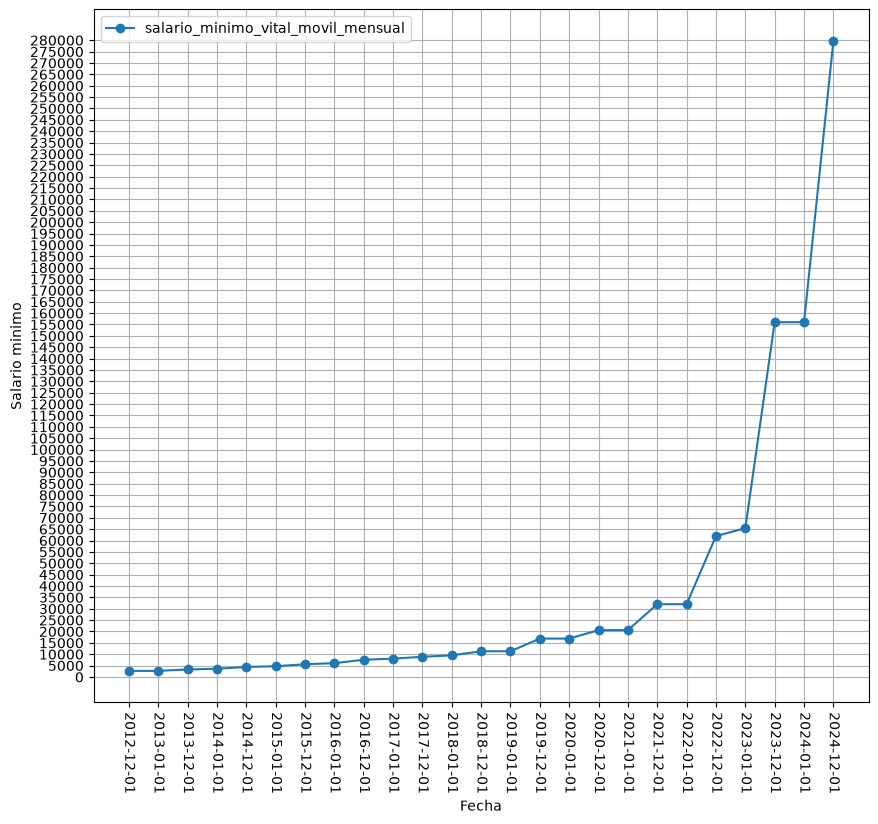

In [81]:
salario_min_desde_2012 = salario_min[(salario_min['indice_tiempo'] >= '2012-12-01') & (salario_min['indice_tiempo'] <= '2024-12-01')]

salario_min_desde_2012 = salario_min_desde_2012[salario_min_desde_2012['indice_tiempo'].dt.month.isin([1,12])]

salario_min_desde_2012 = salario_min_desde_2012.sort_values('indice_tiempo')

salario_min_desde_2012['indice_tiempo'] = salario_min_desde_2012['indice_tiempo'].dt.strftime('%Y-%m-%d')

val_max = int(salario_min_desde_2012['salario_minimo_vital_movil_mensual'].max())
paso = 5000

salario_min_desde_2012.plot(
                            #kind = 'bar',
                            figsize = (10,9),
                            grid = True, 
                            x = 'indice_tiempo',
                            rot = 270,
                            xticks = range(len(salario_min_desde_2012)),
                            xlabel ='Fecha',
                            y = 'salario_minimo_vital_movil_mensual',
                            yticks = range(0, val_max + paso, paso),
                            ylabel ='Salario minimo',
                            marker = 'o'
                           )


<Axes: xlabel='Diciembre del año', ylabel='Variacion porcentual (%)'>

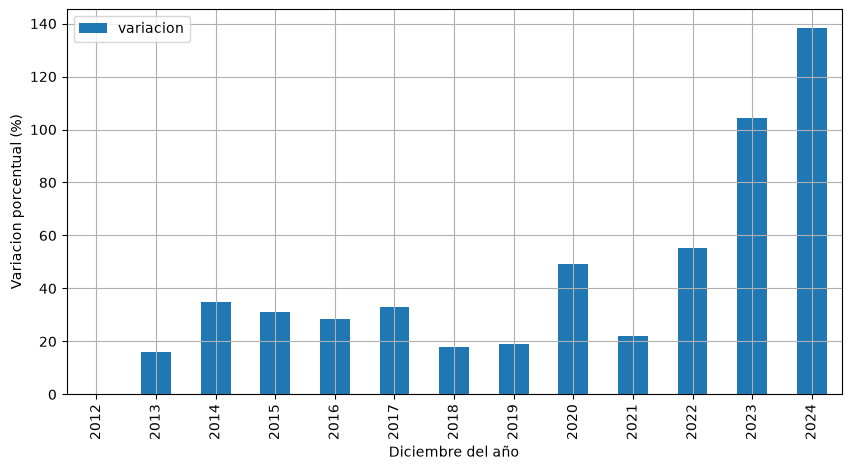

In [82]:
var_salario_min_desde_2012 = salario_min[(salario_min['indice_tiempo'] >= '2011-12-01') & (salario_min['indice_tiempo'] <= '2024-12-01')]

var_salario_min_desde_2012 = var_salario_min_desde_2012[var_salario_min_desde_2012['indice_tiempo'].dt.month == 1]

var_salario_min_desde_2012 = var_salario_min_desde_2012.sort_values('indice_tiempo')

var_salario_min_desde_2012['variacion'] = var_salario_min_desde_2012['salario_minimo_vital_movil_mensual'].pct_change() * 100

var_salario_min_desde_2012['anio'] = var_salario_min_desde_2012['indice_tiempo'].dt.strftime('%Y')

var_salario_min_desde_2012.plot(
                                kind = 'bar',
                                figsize = (10, 5),
                                grid = True,
                                x = 'anio',
                                xlabel = 'Diciembre del año',
                                #xticks=range(len(var_salario_min_desde_2012)),
                                y = 'variacion',
                                ylabel = 'Variacion porcentual (%)',
                                #marker='o'
                               )

<Axes: xlabel='Año', ylabel='Inflacion Acumulada (%)'>

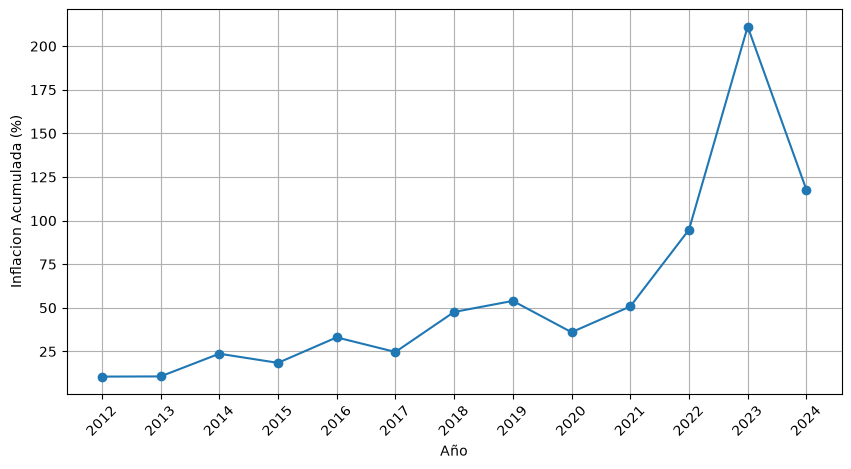

In [83]:
inflacion_2012_2024 = inflacion[(inflacion['fecha'] >= '2012-01-31') & (inflacion['fecha'] <= '2024-12-31')]

anios = []

for fecha in inflacion_2012_2024['fecha']:
    anio = fecha[:4]
    anios.append(anio)

inflacion_2012_2024['fecha'] = anios

inflacion_2012_2024 = inflacion_2012_2024.groupby('fecha')['valor'].apply(
    lambda x: ((1 + x / 100).prod() - 1) * 100
)

inflacion_2012_2024.plot(
                         figsize=(10,5),
                         grid=True,
                         xlabel='Año',
                         xticks=range(len(inflacion_2012_2024)),
                         rot=45,
                         ylabel='Inflacion Acumulada (%)',
                         marker='o'
                        )

<Axes: xlabel='Año', ylabel='Variacion porcentual (%)'>

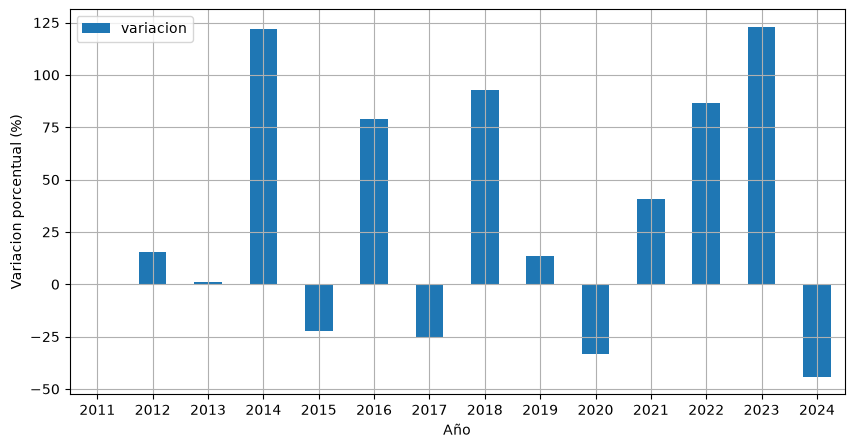

In [84]:
var_inflacion_2012_2024 = inflacion[(inflacion['fecha'] >= '2011-01-31') & (inflacion['fecha'] <= '2024-12-31')]

anios = []

for fecha in var_inflacion_2012_2024['fecha']:
    anio = fecha[:4]
    anios.append(anio)

var_inflacion_2012_2024['fecha'] = anios

var_inflacion_2012_2024 = var_inflacion_2012_2024.groupby('fecha')['valor'].apply(
    lambda x: ((1 + x / 100).prod() - 1) * 100
).reset_index(name='inflacion_acum')

var_inflacion_2012_2024['variacion'] = var_inflacion_2012_2024['inflacion_acum'].pct_change() * 100


var_inflacion_2012_2024.plot(
                             kind = 'bar',
                             figsize = (10, 5),
                             grid = True,
                             x = 'fecha',
                             #xticks = range(len(var_inflacion_2012_2024)),
                             rot = 0,
                             xlabel = 'Año',
                             y = 'variacion',
                             ylabel = 'Variacion porcentual (%)',
                            # marker = 'o'
                            )

GENERAR NUEVOS DATOS

In [85]:
salario_min_desde_2012.to_csv('DATA_PROCESADA/ECONOMIA/salario_min_desde_2012.csv')

var_salario_min_desde_2012.to_csv('DATA_PROCESADA/ECONOMIA/variacion_salario_min_desde_2012.csv')

inflacion_2012_2024.to_csv('DATA_PROCESADA/ECONOMIA/inflacion_2012_2024.csv')

var_inflacion_2012_2024.to_csv('DATA_PROCESADA/ECONOMIA/variacion_inflacion_2012_2024.csv')